# 🎭 FER2013 Facial Emotion Recognition using MobileNetV2
**Complete Google Colab Training & Prediction Pipeline**

This notebook implements transfer learning with **MobileNetV2** for classifying 7 facial emotions:
`angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, `surprise`.

### ⚡ Key Features:
- **Class Imbalance Mitigation:** Calculates and applies balanced class weights so `disgust` (~1.5% of dataset) is properly learned without underfitting.
- **Grayscale to RGB Adapter:** Automatically expands FER2013 1-channel images to 3-channel RGB 96x96 inputs for MobileNetV2.
- **Two-Stage Fine-Tuning:** Stage 1 feature extraction + Stage 2 top-layer unfreezing.
- **Evaluation & Prediction:** Confusion matrix heatmap, per-class classification report, and single image prediction visualizer.

## 🚀 Step 1: Environment & GPU Setup

In [13]:
import os
import sys
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ GPU Active: {gpus[0].name}")
else:
    print("⚠️ GPU not found. Switch to GPU in Colab: Runtime -> Change runtime type -> T4 GPU")

TensorFlow Version: 2.21.0
⚠️ GPU not found. Switch to GPU in Colab: Runtime -> Change runtime type -> T4 GPU


## 📂 Step 2: Unzip Dataset & Path Configuration
Automatically detects and extracts `fer2013.zip` (from Colab root or Google Drive) into `./dataset`.

In [2]:
# If your zip is in Google Drive, uncomment these 2 lines:
# from google.colab import drive
# drive.mount('/content/drive')

# Name of your zip file (e.g. fer2013.zip or path to drive zip)
ZIP_FILE_PATH = 'fer2013.zip'
# Example Drive path: '/content/drive/MyDrive/fer2013.zip'

EXTRACT_TO_DIR = './dataset'

# Unzip automatically if zip file exists
if os.path.exists(ZIP_FILE_PATH):
    print(f"📦 Found '{ZIP_FILE_PATH}'. Unzipping to '{EXTRACT_TO_DIR}'...")
    with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_TO_DIR)
    print("✅ Unzipping complete!")
else:
    print(f"ℹ️ Zip file '{ZIP_FILE_PATH}' not found in current directory. Checking existing extracted folders...")

# Define path to fer2013 folder containing 'train' and 'test'
if os.path.exists('./dataset/fer2013'):
    DATASET_DIR = './dataset/fer2013'
elif os.path.exists('./fer2013'):
    DATASET_DIR = './fer2013'
else:
    DATASET_DIR = './dataset'

TRAIN_DIR = os.path.join(DATASET_DIR, 'train')
TEST_DIR = os.path.join(DATASET_DIR, 'test')

print("Using DATASET_DIR:", DATASET_DIR)
print("Train directory exists:", os.path.exists(TRAIN_DIR))
print("Test directory exists:", os.path.exists(TEST_DIR))

ℹ️ Zip file 'fer2013.zip' not found in current directory. Checking existing extracted folders...
Using DATASET_DIR: ./dataset/fer2013
Train directory exists: True
Test directory exists: True


## ⚖️ Step 3: Analyze Class Distribution & Compute Class Weights

In [3]:
classes = sorted(os.listdir(TRAIN_DIR))
print("Emotion Classes:", classes)

train_counts = {}
total_train_samples = 0
y_train_labels = []

for idx, cls_name in enumerate(classes):
    cls_folder = os.path.join(TRAIN_DIR, cls_name)
    if os.path.isdir(cls_folder):
        count = len(os.listdir(cls_folder))
        train_counts[cls_name] = count
        total_train_samples += count
        y_train_labels.extend([idx] * count)

print(f"\nTotal Training Images: {total_train_samples}")
for cls_name, count in train_counts.items():
    pct = (count / total_train_samples) * 100
    print(f"  - {cls_name:10s}: {count:5d} images ({pct:6.2f}%)")

# Compute balanced class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_labels),
    y=y_train_labels
)
class_weight_dict = dict(enumerate(class_weights))

print("\nComputed Class Weights (higher multiplier = higher loss penalty during training):")
for idx, cls_name in enumerate(classes):
    print(f"  - {cls_name:10s}: {class_weight_dict[idx]:.4f}")

Emotion Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Total Training Images: 28709
  - angry     :  3995 images ( 13.92%)
  - disgust   :   436 images (  1.52%)
  - fear      :  4097 images ( 14.27%)
  - happy     :  7215 images ( 25.13%)
  - neutral   :  4965 images ( 17.29%)
  - sad       :  4830 images ( 16.82%)
  - surprise  :  3171 images ( 11.05%)

Computed Class Weights (higher multiplier = higher loss penalty during training):
  - angry     : 1.0266
  - disgust   : 9.4066
  - fear      : 1.0010
  - happy     : 0.5684
  - neutral   : 0.8260
  - sad       : 0.8491
  - surprise  : 1.2934


## 🔄 Step 4: Data Augmentation & Generators

In [4]:
IMG_SIZE = (96, 96)
BATCH_SIZE = 64

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


## 🏗️ Step 5: MobileNetV2 Model Architecture

In [5]:
def build_mobilenetv2_model(input_shape=(96, 96, 3), num_classes=7):
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False
    
    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs, name='FER2013_MobileNetV2')
    return model, base_model

model, base_model = build_mobilenetv2_model()
model.summary()

Model: "FER2013_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,863 (9.89 MB)

 Trainable params: 332,807 (1.27 MB)

 Non-trainable params: 2,261,056 (8.63 MB)

## 🎯 Step 6: Stage 1 Training - Feature Extraction

In [7]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

callbacks_list = [
    callbacks.ModelCheckpoint(
        'best_mobilenetv2_fer2013.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS_STAGE1 = 10
print("🚀 Starting Stage 1 Training...")
history_stage1 = model.fit(
    train_generator,
    epochs=EPOCHS_STAGE1,
    validation_data=test_generator,
    class_weight=class_weight_dict,
    callbacks=callbacks_list
)

🚀 Starting Stage 1 Training...
Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3466 - loss: 1.6811 - precision: 0.5027 - recall: 0.1184
Epoch 1: val_accuracy improved from None to 0.41335, saving model to best_mobilenetv2_fer2013.h5



Epoch 1: finished saving model to best_mobilenetv2_fer2013.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 1131s 2s/step - accuracy: 0.3466 - loss: 1.6811 - precision: 0.5027 - recall: 0.1184 - val_accuracy: 0.4133 - val_loss: 1.5504 - val_precision: 0.6313 - val_recall: 0.1541 - learning_rate: 0.0010
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.3674 - loss: 1.6159 - precision: 0.5668 - recall: 0.1216
Epoch 2: val_accuracy improved from 0.41335 to 0.42115, saving model to best_mobilenetv2_fer2013.h5



Epoch 2: finished saving model to best_mobilenetv2_fer2013.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 288s 641ms/step - accuracy: 0.3674 - loss: 1.6159 - precision: 0.5668 - recall: 0.1216 - val_accuracy: 0.4211 - val_loss: 1.5164 - val_precision: 0.6841 - val_recall: 0.1442 - learning_rate: 0.0010
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.3725 - loss: 1.5856 - precision: 0.5788 - recall: 0.1242
Epoch 3: val_accuracy did not improve from 0.42115
449/449 ━━━━━━━━━━━━━━━━━━━━ 279s 620ms/step - accuracy: 0.3725 - loss: 1.5856 - precision: 0.5788 - recall: 0.1242 - val_accuracy: 0.4092 - val_loss: 1.5471 - val_precision: 0.6208 - val_recall: 0.1683 - learning_rate: 0.0010
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 539ms/step - accuracy: 0.3777 - loss: 1.5761 - precision: 0.5855 - recall: 0.1298
Epoch 4: val_accuracy did not improve from 0.42115
449/449 ━━━━━━━━━━━━━━━━━━━━ 270s 602ms/step - accuracy: 0.3777 - loss: 1.5761 - precision: 0.5855 - recall: 0.1298 - val_accuracy:


Epoch 6: finished saving model to best_mobilenetv2_fer2013.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 283s 631ms/step - accuracy: 0.3869 - loss: 1.5579 - precision: 0.5978 - recall: 0.1374 - val_accuracy: 0.4245 - val_loss: 1.5130 - val_precision: 0.6841 - val_recall: 0.1442 - learning_rate: 0.0010
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 535ms/step - accuracy: 0.3927 - loss: 1.5326 - precision: 0.5975 - recall: 0.1431
Epoch 7: val_accuracy did not improve from 0.42449
449/449 ━━━━━━━━━━━━━━━━━━━━ 312s 599ms/step - accuracy: 0.3927 - loss: 1.5326 - precision: 0.5975 - recall: 0.1431 - val_accuracy: 0.4163 - val_loss: 1.5319 - val_precision: 0.6513 - val_recall: 0.1613 - learning_rate: 0.0010
Epoch 8/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 539ms/step - accuracy: 0.3921 - loss: 1.5297 - precision: 0.5994 - recall: 0.1474
Epoch 8: val_accuracy improved from 0.42449 to 0.43564, saving model to best_mobilenetv2_fer2013.h5



Epoch 8: finished saving model to best_mobilenetv2_fer2013.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 274s 610ms/step - accuracy: 0.3921 - loss: 1.5297 - precision: 0.5994 - recall: 0.1474 - val_accuracy: 0.4356 - val_loss: 1.4724 - val_precision: 0.6631 - val_recall: 0.1889 - learning_rate: 0.0010
Epoch 9/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 565ms/step - accuracy: 0.3915 - loss: 1.5251 - precision: 0.5829 - recall: 0.1449
Epoch 9: val_accuracy improved from 0.43564 to 0.44079, saving model to best_mobilenetv2_fer2013.h5



Epoch 9: finished saving model to best_mobilenetv2_fer2013.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 286s 636ms/step - accuracy: 0.3915 - loss: 1.5251 - precision: 0.5829 - recall: 0.1449 - val_accuracy: 0.4408 - val_loss: 1.4828 - val_precision: 0.7019 - val_recall: 0.1666 - learning_rate: 0.0010
Epoch 10/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 0.3970 - loss: 1.5225 - precision: 0.6039 - recall: 0.1529
Epoch 10: val_accuracy did not improve from 0.44079
449/449 ━━━━━━━━━━━━━━━━━━━━ 279s 620ms/step - accuracy: 0.3970 - loss: 1.5225 - precision: 0.6039 - recall: 0.1529 - val_accuracy: 0.4358 - val_loss: 1.4756 - val_precision: 0.6493 - val_recall: 0.1999 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 8.


## 🔓 Step 7: Stage 2 Training - Fine-Tuning Top Base Layers

In [ ]:
base_model.trainable = True
fine_tune_at = len(base_model.layers) - 40
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

EPOCHS_STAGE2 = 1 
print("🚀 Starting Stage 2 Fine-Tuning...")
history_stage2 = model.fit(
    train_generator,
    epochs=EPOCHS_STAGE2,
    validation_data=test_generator,
    class_weight=class_weight_dict,
    callbacks=callbacks_list
)

🚀 Starting Stage 2 Fine-Tuning...
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 736ms/step - accuracy: 0.3216 - loss: 1.7422 - precision: 0.4696 - recall: 0.1090
Epoch 1: val_accuracy did not improve from 0.44079
449/449 ━━━━━━━━━━━━━━━━━━━━ 393s 814ms/step - accuracy: 0.3216 - loss: 1.7422 - precision: 0.4696 - recall: 0.1090 - val_accuracy: 0.4093 - val_loss: 1.6563 - val_precision: 0.5312 - val_recall: 0.2598 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 1.


## 📊 Step 8: Comprehensive Model Evaluation

113/113 ━━━━━━━━━━━━━━━━━━━━ 42s 343ms/step

=================== CLASSIFICATION REPORT ===================
              precision    recall  f1-score   support

       angry       0.38      0.14      0.21       958
     disgust       0.11      0.33      0.17       111
        fear       0.33      0.14      0.20      1024
       happy       0.41      0.83      0.55      1774
     neutral       0.44      0.22      0.29      1233
         sad       0.39      0.37      0.38      1247
    surprise       0.65      0.50      0.56       831

    accuracy                           0.41      7178
   macro avg       0.39      0.36      0.34      7178
weighted avg       0.42      0.41      0.37      7178



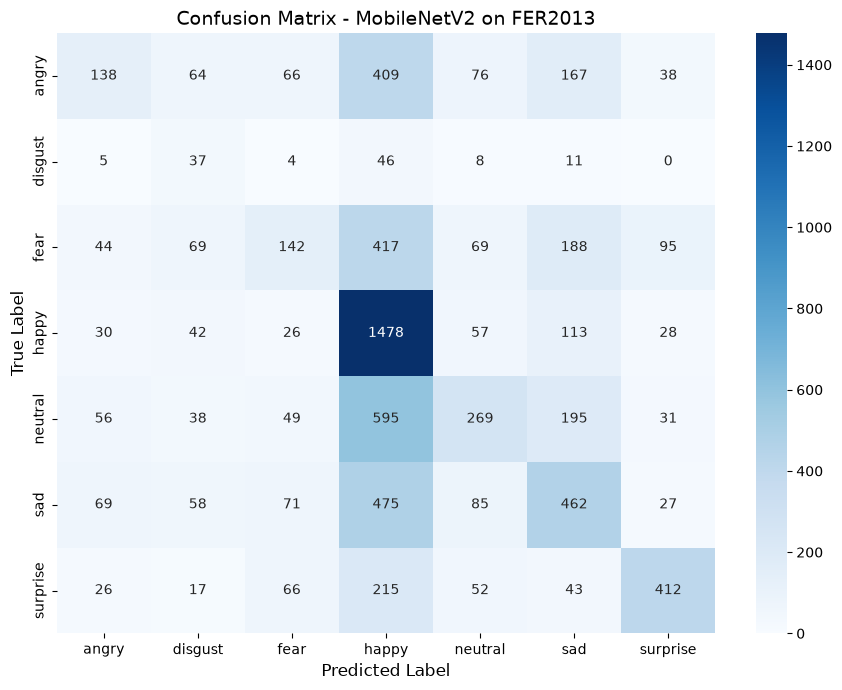

In [9]:
test_generator.reset()
predictions = model.predict(test_generator, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

print("\n=================== CLASSIFICATION REPORT ===================")
print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix - MobileNetV2 on FER2013', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

## 📈 Step 9: Plot Training & Validation Curves

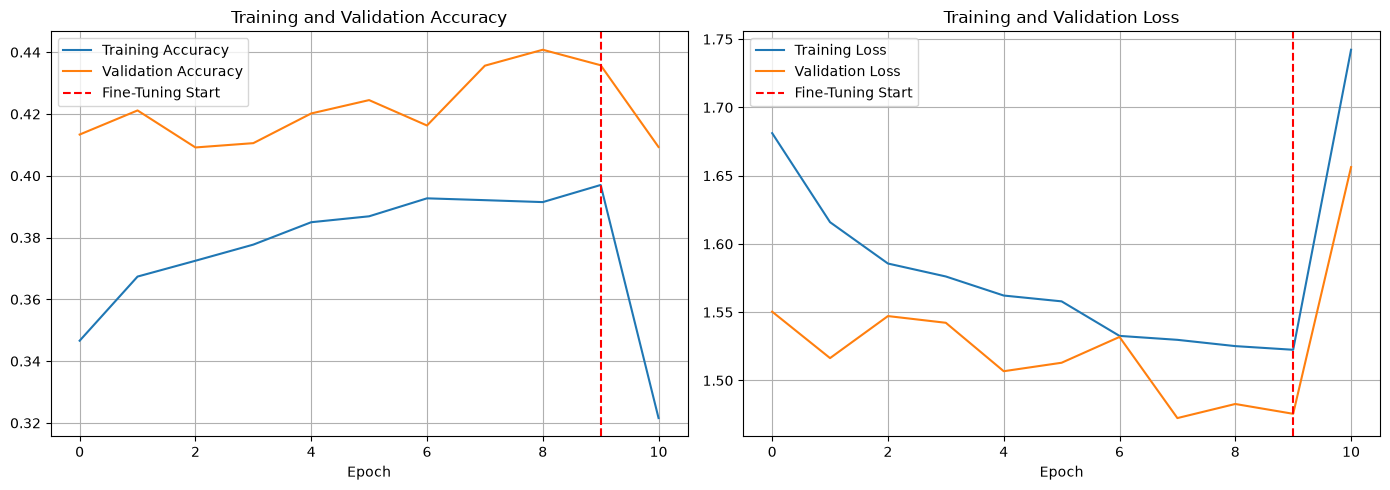

In [10]:
acc = history_stage1.history['accuracy'] + history_stage2.history['accuracy']
val_acc = history_stage1.history['val_accuracy'] + history_stage2.history['val_accuracy']
loss = history_stage1.history['loss'] + history_stage2.history['loss']
val_loss = history_stage1.history['val_loss'] + history_stage2.history['val_loss']

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_stage1.history['accuracy'])-1, color='red', linestyle='--', label='Fine-Tuning Start')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history_stage1.history['loss'])-1, color='red', linestyle='--', label='Fine-Tuning Start')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 🔮 Step 10: Inference Pipeline (Predict Single Image Emotion)

Testing on sample image: ./dataset/fer2013\test\disgust\PrivateTest_11895083.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


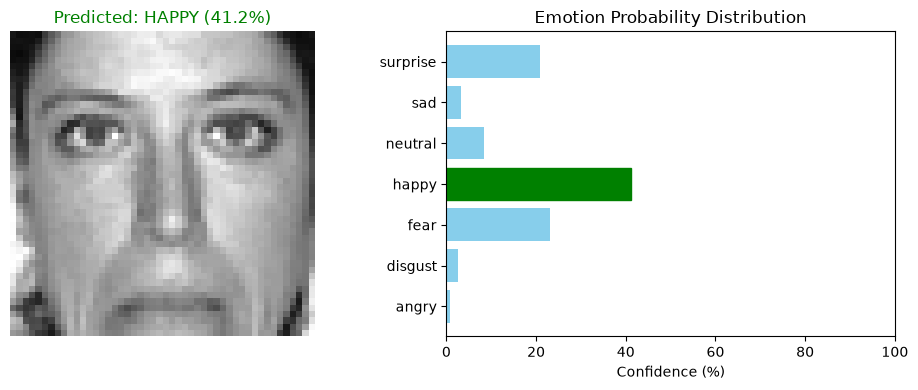

In [12]:
from tensorflow.keras.preprocessing import image

def predict_facial_emotion(img_path, model, class_names=classes):
    img = image.load_img(img_path, target_size=(96, 96), color_mode='rgb')
    img_array = image.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)
    img_preprocessed = preprocess_input(img_batch)
    
    preds = model.predict(img_preprocessed)[0]
    pred_class_idx = np.argmax(preds)
    pred_class_name = class_names[pred_class_idx]
    confidence = preds[pred_class_idx] * 100
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    raw_img = image.load_img(img_path)
    ax1.imshow(raw_img)
    ax1.set_title(f"Predicted: {pred_class_name.upper()} ({confidence:.1f}%)", fontsize=12, color='green')
    ax1.axis('off')
    
    bars = ax2.barh(class_names, preds * 100, color='skyblue')
    bars[pred_class_idx].set_color('green')
    ax2.set_xlim(0, 100)
    ax2.set_xlabel('Confidence (%)')
    ax2.set_title('Emotion Probability Distribution')
    plt.tight_layout()
    plt.show()
    return pred_class_name, confidence

# Example usage:
sample_disgust_dir = os.path.join(TEST_DIR, 'disgust')
if os.path.exists(sample_disgust_dir) and len(os.listdir(sample_disgust_dir)) > 0:
    sample_test_img = os.path.join(sample_disgust_dir, os.listdir(sample_disgust_dir)[0])
    print(f"Testing on sample image: {sample_test_img}")
    predicted_emotion, conf = predict_facial_emotion(sample_test_img, model)